# Лабораторная работа №2. Разработка сверточной нейронной сети с использованием PyTorch

In [1]:
import os
import random

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__}, вычисления на устройстве: {device}")

PyTorch 2.15.0+cu132, вычисления на устройстве: cuda


In [2]:
DATA_DIR = os.environ.get("CIFAR10_DATA", "./data")

MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

train_set = datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=train_transform)
test_set = datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=test_transform)

BATCH_SIZE = 128
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=2, pin_memory=True)
classes = train_set.classes
print(f"Классы ({len(classes)}): {classes}")

Классы (10): ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [3]:
print(f"Обучающая выборка: {len(train_set)} изображений")
print(f"Форма меток: {torch.tensor(train_set.targets).shape}")
print(f"Тестовая выборка: {len(test_set)} изображений")
print(f"Форма меток: {torch.tensor(test_set.targets).shape}")

img, label = train_set[0]
print(f"Форма одного изображения: {tuple(img.shape)} (каналы, высота, ширина)")

Обучающая выборка: 50000 изображений
Форма меток: torch.Size([50000])
Тестовая выборка: 10000 изображений
Форма меток: torch.Size([10000])
Форма одного изображения: (3, 32, 32) (каналы, высота, ширина)


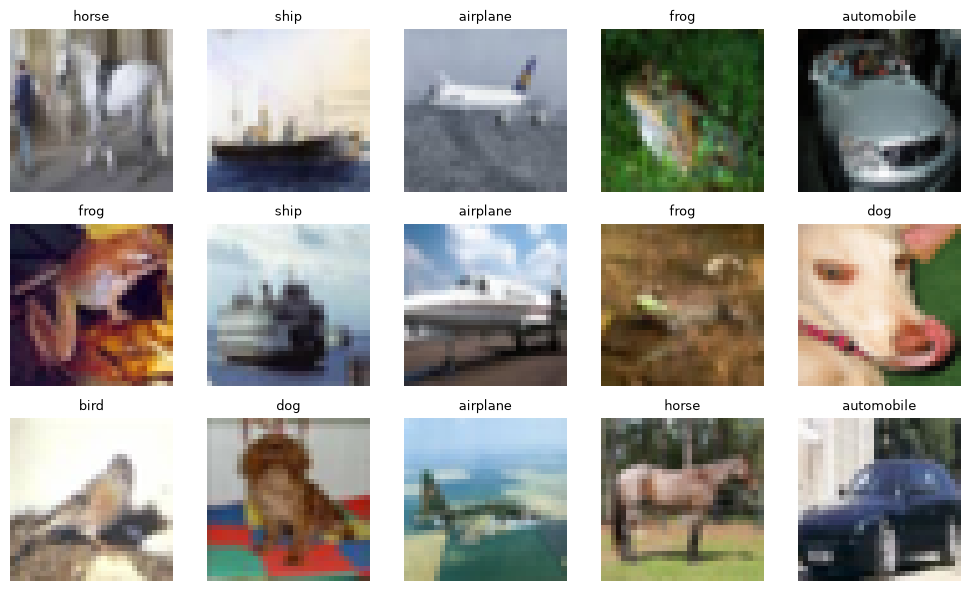

In [4]:
raw_train = datasets.CIFAR10(DATA_DIR, train=True, download=False,
                             transform=transforms.ToTensor())

fig, axes = plt.subplots(3, 5, figsize=(10, 6))
for ax, idx in zip(axes.flat, np.random.permutation(len(raw_train))[:30]):
    img, label = raw_train[idx]
    ax.imshow(img.permute(1, 2, 0).numpy())
    ax.set_title(classes[label], fontsize=9)
    ax.axis("off") 
plt.tight_layout()
plt.show()

In [5]:
class ConvBlock(nn.Module):

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class VGGNet(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        config = [64, 64, "M", 128, 128, "M", 256, 256, "M", 512, 512, "M"]
        layers = []
        in_channels = 3
        for value in config:
            if value == "M":
                layers.append(nn.MaxPool2d(kernel_size=2))
            else:
                layers.append(ConvBlock(in_channels, value))
                in_channels = value
        self.features = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_channels, num_classes),
        )

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        return self.classifier(x)

In [6]:
model = VGGNet(num_classes=10).to(device)
print(model)

VGGNet(
  (features): Sequential(
    (0): ConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (1): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): ConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        (2): ReLU(inplace=True)
      )
    )
    (4): ConvBloc

In [7]:
EPOCHS = 60
LEARNING_RATE = 0.1
WEIGHT_DECAY = 5e-4

criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE,
                      momentum=0.9, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

In [8]:
def train_one_epoch(model, loader, criterion, optimizer):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        logits = model(images)
        total_loss += criterion(logits, labels).item() * labels.size(0)
        correct += (logits.argmax(dim=1) == labels).sum().item()
        total += labels.size(0)
    return total_loss / total, correct / total

In [9]:
history = {"train_loss": [], "train_acc": []}

print("Тренировочная выборка:")
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer)

    scheduler.step()

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)

    print(
        f"Эпоха {epoch}/{EPOCHS}: "
        f"loss {train_loss:.4f}, точность {train_acc:.4f}, ошибка {1 - train_acc:.4f}"
    )

Тренировочная выборка:
Эпоха 1/60: loss 1.9987, точность 0.2959, ошибка 0.7041
Эпоха 2/60: loss 1.3293, точность 0.5123, ошибка 0.4877
Эпоха 3/60: loss 1.0219, точность 0.6334, ошибка 0.3666
Эпоха 4/60: loss 0.8226, точность 0.7111, ошибка 0.2889
Эпоха 5/60: loss 0.6978, точность 0.7576, ошибка 0.2424
Эпоха 6/60: loss 0.6276, точность 0.7842, ошибка 0.2158
Эпоха 7/60: loss 0.5831, точность 0.8010, ошибка 0.1990
Эпоха 8/60: loss 0.5455, точность 0.8144, ошибка 0.1856
Эпоха 9/60: loss 0.5171, точность 0.8219, ошибка 0.1781
Эпоха 10/60: loss 0.4919, точность 0.8312, ошибка 0.1688
Эпоха 11/60: loss 0.4813, точность 0.8350, ошибка 0.1650
Эпоха 12/60: loss 0.4551, точность 0.8443, ошибка 0.1557
Эпоха 13/60: loss 0.4479, точность 0.8466, ошибка 0.1534
Эпоха 14/60: loss 0.4251, точность 0.8551, ошибка 0.1449
Эпоха 15/60: loss 0.4125, точность 0.8574, ошибка 0.1426
Эпоха 16/60: loss 0.4005, точность 0.8627, ошибка 0.1373
Эпоха 17/60: loss 0.3909, точность 0.8663, ошибка 0.1337
Эпоха 18/60: loss

In [10]:
test_loss, test_acc = evaluate(model, test_loader, criterion)
print(f"Тестовая выборка: точность {test_acc:.4f}, ошибка классификации {1 - test_acc:.4f}")

Тестовая выборка: точность 0.9332, ошибка классификации 0.0668


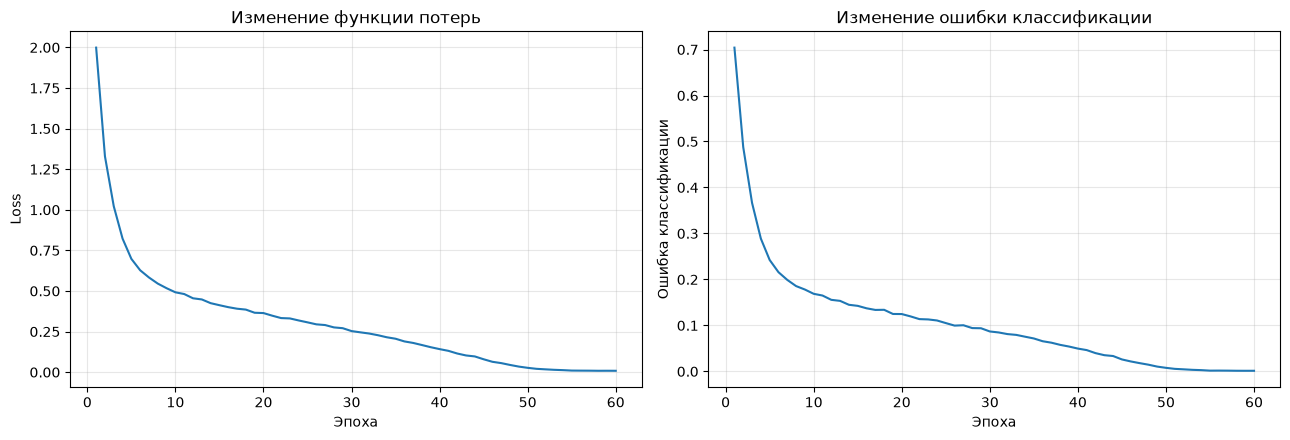

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

epochs = np.arange(1, EPOCHS + 1)

ax1.plot(epochs, history["train_loss"])
ax1.set_xlabel("Эпоха")
ax1.set_ylabel("Loss")
ax1.set_title("Изменение функции потерь")
ax1.grid(alpha=0.3)

train_error = [1 - acc for acc in history["train_acc"]]
ax2.plot(epochs, train_error)
ax2.set_xlabel("Эпоха")
ax2.set_ylabel("Ошибка классификации")
ax2.set_title("Изменение ошибки классификации")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()